# 🏦 Projet : Prédiction de Défaut de Paiement (Home Credit)
**Objectif** : Développer un modèle de Machine Learning capable d'évaluer le risque de défaut de paiement d'un client.

Ce notebook est structuré en deux parties :
1. **Modèle Baseline** : Entraînement sur la table principale avec un Feature Engineering basique.
2. **Modèle Avancé** : Intégration de l'historique de crédit externe et des comportements de paiement pour améliorer la performance (ROC-AUC).

In [1]:
# ==========================================
# 📦 IMPORTATION DES LIBRAIRIES
# ==========================================
import pandas as pd
import numpy as np
import gc

# Modélisation et Évaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report
import lightgbm as lgb

# Options d'affichage Pandas
pd.set_option('display.max_columns', 100)
import warnings
warnings.filterwarnings('ignore')

print("Librairies chargées avec succès.")

Librairies chargées avec succès.


---
## 🚀 Partie 1 : Analyse Initiale et Modèle Baseline
Chargement de la table principale `application_train.csv`, analyse de la variable cible et création de ratios financiers classiques.

In [2]:
# 1. Chargement des données principales
print("Chargement de application_train.csv...")
df_app = pd.read_csv("data/application_train.csv")
print(f"Dimensions de la table : {df_app.shape[0]} lignes, {df_app.shape[1]} colonnes\n")

# 2. Analyse du déséquilibre de classes (Target)
target_counts = df_app['TARGET'].value_counts(normalize=True) * 100
print("--- Répartition de la cible (TARGET) ---")
print(f"0 (Prêt remboursé)       : {target_counts[0]:.2f}%")
print(f"1 (Défaut de paiement)   : {target_counts[1]:.2f}%\n")

# 3. Feature Engineering métier basique
df_app['CREDIT_INCOME_RATIO'] = df_app['AMT_CREDIT'] / (df_app['AMT_INCOME_TOTAL'] + 1e-5)
df_app['ANNUITY_INCOME_RATIO'] = df_app['AMT_ANNUITY'] / (df_app['AMT_INCOME_TOTAL'] + 1e-5)

# Correction de la valeur aberrante pour les retraités (365243)
df_app['DAYS_EMPLOYED'] = df_app['DAYS_EMPLOYED'].replace(365243, np.nan)
df_app['EMPLOYED_TO_AGE_RATIO'] = df_app['DAYS_EMPLOYED'] / (df_app['DAYS_BIRTH'] - 1e-5)

df_app.head(3)

Chargement de application_train.csv...


Dimensions de la table : 307511 lignes, 122 colonnes

--- Répartition de la cible (TARGET) ---
0 (Prêt remboursé)       : 91.93%
1 (Défaut de paiement)   : 8.07%



,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,EMPLOYED_TO_AGE_RATIO
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637.0,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,...,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0,2.007889,0.121978,0.067329
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188.0,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,...,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,4.790750,0.132217,0.070862
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225.0,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-815.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,2.000000,0.100000,0.011814


In [3]:
# 4. Préparation pour LightGBM (Baseline)
X_base = df_app.drop(columns=['SK_ID_CURR', 'TARGET'])
y_base = df_app['TARGET']

# Typage des variables catégorielles pour LightGBM
for col in X_base.select_dtypes(include=['object']).columns:
    X_base[col] = X_base[col].astype('category')

X_train_b, X_val_b, y_train_b, y_val_b = train_test_split(
    X_base, y_base, test_size=0.2, random_state=42, stratify=y_base
)

# 5. Entraînement du modèle Baseline
print("Entraînement du modèle LightGBM Baseline...")
model_base = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    class_weight='balanced', 
    random_state=42,
    n_jobs=-1
)

model_base.fit(
    X_train_b, y_train_b,
    eval_set=[(X_val_b, y_val_b)],
    eval_metric='auc',
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

# 6. Évaluation Baseline
y_pred_proba_b = model_base.predict_proba(X_val_b)[:, 1]
auc_score_b = roc_auc_score(y_val_b, y_pred_proba_b)
print(f">>> Score ROC-AUC Baseline : {auc_score_b:.4f} <<<")

Entraînement du modèle LightGBM Baseline...


[LightGBM] [Info] Number of positive: 19860, number of negative: 226148


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.127559 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 12172
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 119
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000


>>> Score ROC-AUC Baseline : 0.7603 <<<


---
## 🧠 Partie 2 : Feature Engineering Avancé (Jointures Multi-Tables)
Nous allons maintenant exploiter les données relationnelles (`bureau.csv` et `installments_payments.csv`) pour capter l'historique bancaire des clients et améliorer la capacité prédictive du modèle.

In [4]:
# 1. Chargement des tables secondaires
print("Chargement des tables annexes...")
bureau = pd.read_csv("data/bureau.csv")
installments = pd.read_csv("data/installments_payments.csv")

# 2. Agrégation de l'historique de crédit externe (Bureau)
print("Agrégation des données Bureau...")
bureau_agg = bureau.groupby('SK_ID_CURR').agg({
    'SK_ID_BUREAU': 'count',                 
    'AMT_CREDIT_SUM': ['sum', 'mean'],       
    'AMT_CREDIT_SUM_DEBT': ['sum', 'mean'],  
    'DAYS_CREDIT': ['min', 'max', 'mean']    
})
bureau_agg.columns = ['BUREAU_' + '_'.join(col).strip().upper() for col in bureau_agg.columns.values]
bureau_agg = bureau_agg.reset_index()

# 3. Agrégation du comportement de paiement (Installments)
print("Agrégation des comportements de paiement...")
installments['LATE_PAYMENT'] = (installments['DAYS_ENTRY_PAYMENT'] > installments['DAYS_INSTALMENT']).astype(int)
installments['UNDER_PAYMENT'] = (installments['AMT_PAYMENT'] < installments['AMT_INSTALMENT']).astype(int)

installments_agg = installments.groupby('SK_ID_CURR').agg({
    'NUM_INSTALMENT_VERSION': 'count',       
    'LATE_PAYMENT': ['sum', 'mean'],         
    'UNDER_PAYMENT': ['sum', 'mean'],        
    'AMT_PAYMENT': ['sum', 'mean']           
})
installments_agg.columns = ['INSTALL_' + '_'.join(col).strip().upper() for col in installments_agg.columns.values]
installments_agg = installments_agg.reset_index()

print("Agrégations terminées.")

Chargement des tables annexes...


Agrégation des données Bureau...


Agrégation des comportements de paiement...


Agrégations terminées.


In [5]:
# 4. Jointure des tables (Left Join)
print("Fusion des tables...")
df_merged = df_app.merge(bureau_agg, on='SK_ID_CURR', how='left')
df_merged = df_merged.merge(installments_agg, on='SK_ID_CURR', how='left')

# Libération de la RAM
del bureau, installments, bureau_agg, installments_agg
gc.collect()

print(f"Nouvelles dimensions du dataset : {df_merged.shape[0]} lignes, {df_merged.shape[1]} colonnes")

Fusion des tables...


Nouvelles dimensions du dataset : 307511 lignes, 140 colonnes


In [6]:
# 5. Entraînement du modèle avancé
X_adv = df_merged.drop(columns=['SK_ID_CURR', 'TARGET'])
y_adv = df_merged['TARGET']

for col in X_adv.select_dtypes(include=['object']).columns:
    X_adv[col] = X_adv[col].astype('category')

X_train_adv, X_val_adv, y_train_adv, y_val_adv = train_test_split(
    X_adv, y_adv, test_size=0.2, random_state=42, stratify=y_adv
)

print("Entraînement du modèle LightGBM Avancé...")
model_adv = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

model_adv.fit(
    X_train_adv, y_train_adv,
    eval_set=[(X_val_adv, y_val_adv)],
    eval_metric='auc',
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

y_pred_proba_adv = model_adv.predict_proba(X_val_adv)[:, 1]
auc_score_adv = roc_auc_score(y_val_adv, y_pred_proba_adv)

print(f"\n>>> NOUVEAU Score ROC-AUC (avec Feature Engineering) : {auc_score_adv:.4f} <<<")
print(f"Amélioration de : {auc_score_adv - auc_score_b:.4f} points AUC")

Entraînement du modèle LightGBM Avancé...


[LightGBM] [Info] Number of positive: 19860, number of negative: 226148


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.272443 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 15472
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 134


[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000



>>> NOUVEAU Score ROC-AUC (avec Feature Engineering) : 0.7690 <<<
Amélioration de : 0.0087 points AUC


---
## 📊 Interprétation des résultats
Analyse des caractéristiques (features) ayant le plus influencé les décisions de l'algorithme après l'ajout des bases de données de l'historique bancaire.

In [7]:
# Top 15 des variables les plus importantes du modèle final
importances = pd.DataFrame({
    'Feature': X_adv.columns,
    'Importance': model_adv.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("--- Top 15 des variables décisives ---")
display(importances.head(15))

--- Top 15 des variables décisives ---


,Feature,Importance
38,ORGANIZATION_TYPE,1776
41,EXT_SOURCE_3,527
39,EXT_SOURCE_1,500
40,EXT_SOURCE_2,485
136,INSTALL_AMT_PAYMENT_SUM,316
6,AMT_CREDIT,290
15,DAYS_BIRTH,284
26,OCCUPATION_TYPE,278
129,BUREAU_DAYS_CREDIT_MAX,271
133,INSTALL_LATE_PAYMENT_MEAN,248


---
## 🔁 Partie 3 : Une évaluation plus rigoureuse (validation croisée à 5 plis)
En relisant les parties 1 et 2, deux biais apparaissent :
1. **Le même jeu de validation sert à l'early stopping *et* au score annoncé** : le nombre d'arbres est choisi pour maximiser l'AUC
   sur ce jeu, donc l'AUC annoncée est légèrement optimiste.
2. **L'importance par défaut compte le nombre de coupes** : une variable catégorielle avec beaucoup de modalités
   (`ORGANIZATION_TYPE`) offre beaucoup de coupes possibles et paraît importante même si chaque coupe apporte peu.

**Correction** : validation croisée stratifiée à 5 plis. Dans chaque pli, l'early stopping utilise une petite partie (10 %)
du **train** ; le pli de validation ne sert **qu'à mesurer**. On compare la baseline et le modèle avancé **sur les mêmes plis**,
et on mesure l'importance des variables par **gain** (réduction totale de la perte). Compter ~15 à 25 minutes.

In [8]:
from sklearn.model_selection import StratifiedKFold

def cross_validate(X, y, n_splits=5, seed=42):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(len(y))
    fold_aucs, importances = [], []
    for k, (tr, va) in enumerate(skf.split(X, y)):
        # early stopping sur 10 % du train : le pli de validation reste intact
        tr_fit, tr_es = train_test_split(tr, test_size=0.1, random_state=seed, stratify=y.iloc[tr])
        model = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, class_weight='balanced',
                                   random_state=seed, n_jobs=-1, verbose=-1)
        model.fit(X.iloc[tr_fit], y.iloc[tr_fit], eval_set=[(X.iloc[tr_es], y.iloc[tr_es])], eval_metric='auc',
                  callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)])
        oof[va] = model.predict_proba(X.iloc[va])[:, 1]
        fold_aucs.append(roc_auc_score(y.iloc[va], oof[va]))
        importances.append(pd.Series(model.booster_.feature_importance(importance_type='gain'), index=X.columns))
        print(f"  pli {k + 1} : AUC = {fold_aucs[-1]:.4f} ({model.best_iteration_} arbres)")
    importance = pd.concat(importances, axis=1).mean(axis=1).sort_values(ascending=False)
    return np.array(fold_aucs), roc_auc_score(y, oof), importance

print("Baseline (table principale) :")
auc_folds_base, oof_auc_base, _ = cross_validate(X_base, y_base)
print("Modèle avancé (+ bureau + remboursements) :")
auc_folds_adv, oof_auc_adv, importance_gain = cross_validate(X_adv, y_adv)

Baseline (table principale) :


  pli 1 : AUC = 0.7544 (237 arbres)


  pli 2 : AUC = 0.7634 (207 arbres)


  pli 3 : AUC = 0.7552 (179 arbres)


  pli 4 : AUC = 0.7619 (201 arbres)


  pli 5 : AUC = 0.7528 (306 arbres)
Modèle avancé (+ bureau + remboursements) :


  pli 1 : AUC = 0.7660 (199 arbres)


  pli 2 : AUC = 0.7712 (203 arbres)


  pli 3 : AUC = 0.7647 (227 arbres)


  pli 4 : AUC = 0.7700 (247 arbres)


  pli 5 : AUC = 0.7646 (345 arbres)


In [9]:
delta = auc_folds_adv - auc_folds_base   # mêmes plis -> comparaison appariée
resume = pd.DataFrame({
    'AUC out-of-fold': [oof_auc_base, oof_auc_adv],
    'AUC moyenne des plis': [auc_folds_base.mean(), auc_folds_adv.mean()],
    'écart-type entre plis': [auc_folds_base.std(), auc_folds_adv.std()],
}, index=['Baseline', 'Avancé']).round(4)
display(resume)
print(f"Gain du modèle avancé, pli par pli : {np.round(delta, 4)}")
print(f"Gain moyen = {delta.mean():.4f} ± {delta.std():.4f} ; positif sur {(delta > 0).sum()}/{len(delta)} plis")

,AUC out-of-fold,AUC moyenne des plis,écart-type entre plis
Baseline,0.7575,0.7576,0.0043
Avancé,0.7672,0.7673,0.0028


Gain du modèle avancé, pli par pli : [0.0116 0.0078 0.0095 0.0082 0.0118]
Gain moyen = 0.0098 ± 0.0017 ; positif sur 5/5 plis


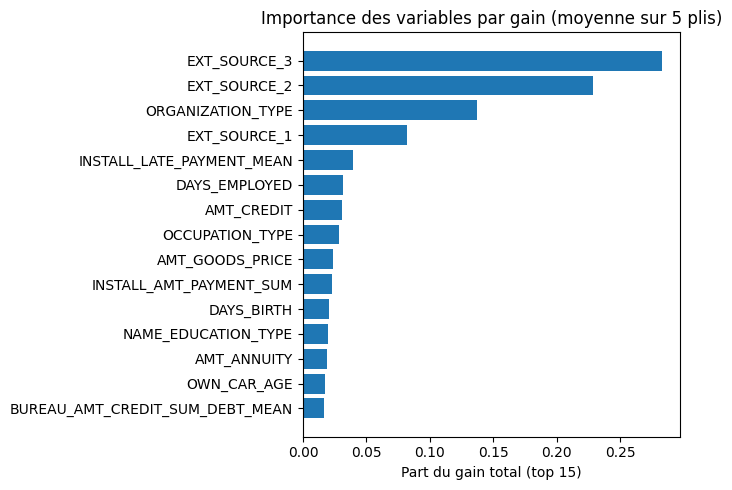

In [10]:
import matplotlib.pyplot as plt

top = importance_gain.head(15)[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values / top.values.sum())
plt.xlabel("Part du gain total (top 15)")
plt.title("Importance des variables par gain (moyenne sur 5 plis)")
plt.tight_layout()
plt.show()

### Conclusion
- **Résultats initiaux (parties 1 et 2, une seule séparation 80/20)** : AUC 0,7603 → 0,7690 avec l'historique de crédit externe
  et le comportement de remboursement.
- **Partie 3** : la validation croisée donne une estimation plus fiable (moyenne et écart-type sur 5 plis), et la comparaison
  appariée montre si le gain apporté par les tables d'historique est **stable d'un pli à l'autre**.
- L'importance par **gain** remplace le comptage de coupes, biaisé en faveur des catégories à nombreuses modalités.
- Pistes : recalibrer les probabilités (`class_weight='balanced'` les décale vers le haut), expliquer chaque décision avec SHAP,
  ajouter `previous_application.csv` et des variables récentes (retards des 6 derniers mois).